In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

iris = pd.read_csv('data/iris_1D_2c.csv')
X = iris.iloc[:, 0].to_numpy()
y = iris.iloc[:, 1].to_numpy().astype(np.uint8)

print(f'X: {X}')
print(f'y: {y}')


X: [1.4 1.3 1.5 4.5 4.1 4.6]
y: [0 0 0 1 1 1]


In [95]:
X = X.reshape(len(X), -1)
X

array([[1.4],
       [1.3],
       [1.5],
       [4.5],
       [4.1],
       [4.6]])

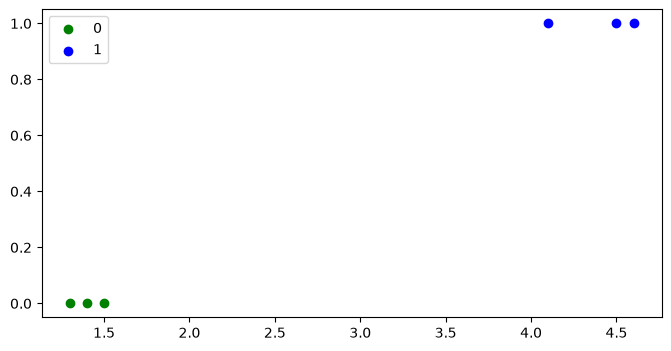

In [96]:
plt.figure(figsize=(8, 4))
plt.scatter(X[y == 0][:, 0], y[y == 0], color = 'g', label = '0')
plt.scatter(X[y == 1][:, 0], y[y == 1], color = 'b', label = '1')
plt.legend()
plt.show()

In [97]:
def one_hot_encoding(y, k):
    one_hot = np.zeros((len(y), k))
    one_hot[np.arange(len(y)), y] = 1
    return one_hot

y_one_hot = one_hot_encoding(y, 2)
print(y_one_hot)

[[1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [98]:
N = len(y)
w = np.array([
    [0.2],
    [-0.1]
])
b = np.array([
    [0.1],
    [0.05]
])

print(f'w: {w}')
print(f'b: {b}')

w: [[ 0.2]
 [-0.1]]
b: [[0.1 ]
 [0.05]]


In [99]:
learning_rate = 0.1
losses = []
max_epoch = 100
for epoch in range(max_epoch):
    for i in range(N):
        xi = X[i]
        yi = y_one_hot[i].reshape((2, 1))

        z = xi * w + b

        exp_z = np.exp(z)
        y_hat = exp_z / np.sum(exp_z, axis = 0)
        print(y_hat)

        loss = -yi.T.dot(np.log(y_hat))
        losses.append(loss[0])
        print(loss)
        dw = xi * (y_hat - yi)
        db = y_hat - yi

        w = w - learning_rate * dw
        b = b - learning_rate * db

[[0.61538376]
 [0.38461624]]
[[0.48550921]]
[[0.65856897]
 [0.34143103]]
[[0.41768602]]
[[0.71908075]
 [0.28091925]]
[[0.32978162]]
[[0.94607487]
 [0.05392513]]
[[2.92015864]]
[[0.25964734]
 [0.74035266]]
[[0.30062864]]
[[0.09845725]
 [0.90154275]]
[[0.10364781]]
[[0.30717742]
 [0.69282258]]
[[1.18032978]]
[[0.4097075]
 [0.5902925]]
[[0.89231178]]
[[0.47677978]
 [0.52322022]]
[[0.74070056]]
[[0.5094457]
 [0.4905543]]
[[0.71221931]]
[[0.12830358]
 [0.87169642]]
[[0.13731406]]
[[0.06357748]
 [0.93642252]]
[[0.06568849]]
[[0.31924944]
 [0.68075056]]
[[1.14178254]]
[[0.42456011]
 [0.57543989]]
[[0.85670167]]
[[0.48379391]
 [0.51620609]]
[[0.72609627]]
[[0.4206718]
 [0.5793282]]
[[0.54588612]]
[[0.13265684]
 [0.86734316]]
[[0.14232057]]
[[0.06342718]
 [0.93657282]]
[[0.065528]]
[[0.35502923]
 [0.64497077]]
[[1.03555517]]
[[0.46033908]
 [0.53966092]]
[[0.77579192]]
[[0.51175114]
 [0.48824886]]
[[0.66991683]]
[[0.38665332]
 [0.61334668]]
[[0.48882495]]
[[0.1352425]
 [0.8647575]]
[[0.14530615]

In [100]:
print(w)
print(b)

[[-1.11662847]
 [ 1.21662847]]
[[ 3.13085488]
 [-2.98085488]]


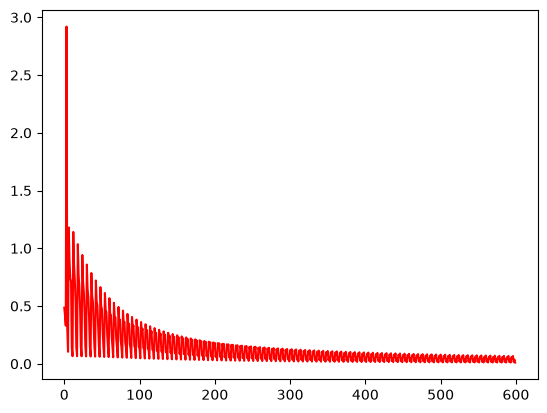

In [101]:
x_axis = range(len(losses))
plt.plot(x_axis, losses, color = 'r')
plt.show()

In [104]:
scores = []
for i in range(N):
    xi = X[i]
    yi = y_one_hot[i].reshape(2, 1)
    z = xi * w + b
    scores.append(z)
    print(z.shape)
scores = np.array(scores)
print(scores)

(2, 1)
(2, 1)
(2, 1)
(2, 1)
(2, 1)
(2, 1)
[[[ 1.56757503]
  [-1.27757503]]

 [[ 1.67923788]
  [-1.39923788]]

 [[ 1.45591218]
  [-1.15591218]]

 [[-1.89397321]
  [ 2.49397321]]

 [[-1.44732183]
  [ 2.00732183]]

 [[-2.00563606]
  [ 2.61563606]]]


In [103]:
predicted_class = np.argmax(scores, axis = 1)
predicted_class

array([[0],
       [0],
       [0],
       [1],
       [1],
       [1]])